
# Primer Modelo de Predicción con Regresión Lineal
 
 
## La regresión lineal es un algoritmo estadístico fundamental que modela la relación lineal entre una variable dependiente y una o más variables independientes. Es la base para muchos métodos de machine learning y proporciona interpretabilidad y simplicidad.

## Modelo de Regresión Lineal Simple Para una variable predictora:
 
# $$y = \beta_0 + \beta_1 x + \epsilon$$

## donde:
## - $y$: Variable dependiente (target)
## - $x$: Variable independiente (predictor)
## - $\beta_0$: Intercepto (término constante)
## - $\beta_1$: Pendiente (coeficiente)
## - $\epsilon$: Error aleatorio


In [2]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [7]:
# Configuración de estilo
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

print("=== Primer Modelo de Regresión Lineal ===")

=== Primer Modelo de Regresión Lineal ===


# Generación de Datos Sintéticos

## Crearemos datos con una relación lineal clara para demostrar los conceptos básicos.

In [10]:
def generar_datos_lineales(n_muestras=200, ruido=1.5):
    """
    Genera datos con relación lineal: y = 2.5*x + 10 + ruido
    """
    np.random.seed(42)
    
    # Generar variable predictora
    x = np.random.uniform(-10, 10, n_muestras)
    
    # Relación lineal con ruido
    y = 2.5 * x + 10 + np.random.normal(0, ruido, n_muestras)
    
    # Crear DataFrame
    datos = pd.DataFrame({
        'x': x,
        'y': y
    })
    
    return datos

# Generar datos
datos = generar_datos_lineales(n_muestras=200, ruido=2.0)
print("Dimensiones del dataset:", datos.shape)
print("\nPrimeras 5 filas:")
print(datos.head())

Dimensiones del dataset: (200, 2)

Primeras 5 filas:
          x          y
0 -2.509198   2.366956
1  9.014286  33.000223
2  4.639879  22.185842
3  1.973170  13.504221
4 -6.879627  -3.467519


### Elaboramos un análisis estadístico exploratorio básico

In [12]:

print("Estadísticas descriptivas:")
print(datos.describe())

Estadísticas descriptivas:
                x           y
count  200.000000  200.000000
mean    -0.319875    9.335140
std      5.897829   14.825679
min     -9.889558  -16.250812
25%     -5.428352   -3.772614
50%     -0.110275    8.718941
75%      5.137192   22.444929
max      9.737739   36.837852


### Elaboramos un análisis de Visualización de los datos, buscando relaciones entre variables

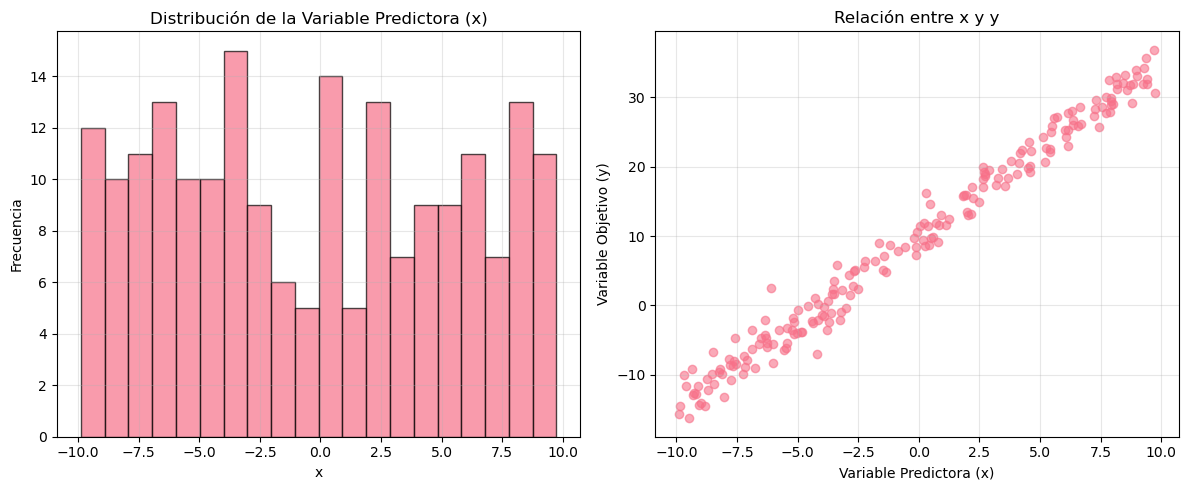

In [14]:
plt.figure(figsize=(12, 5))

# Distribución de x
plt.subplot(1, 2, 1)
plt.hist(datos['x'], bins=20, alpha=0.7, edgecolor='black')
plt.title('Distribución de la Variable Predictora (x)')
plt.xlabel('x')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)

# Relación x vs y
plt.subplot(1, 2, 2)
plt.scatter(datos['x'], datos['y'], alpha=0.6)
plt.title('Relación entre x y y')
plt.xlabel('Variable Predictora (x)')
plt.ylabel('Variable Objetivo (y)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#  Análisis de Correlación

### La correlación mide la fuerza y dirección de la relación entre dos variables. Con sus valores podemos establecer si el modelo debe ser lineal o de otro tipo.

Correlación entre x e y: 0.9914
Interpretación: Fuerte correlación lineal
Dirección: Positiva


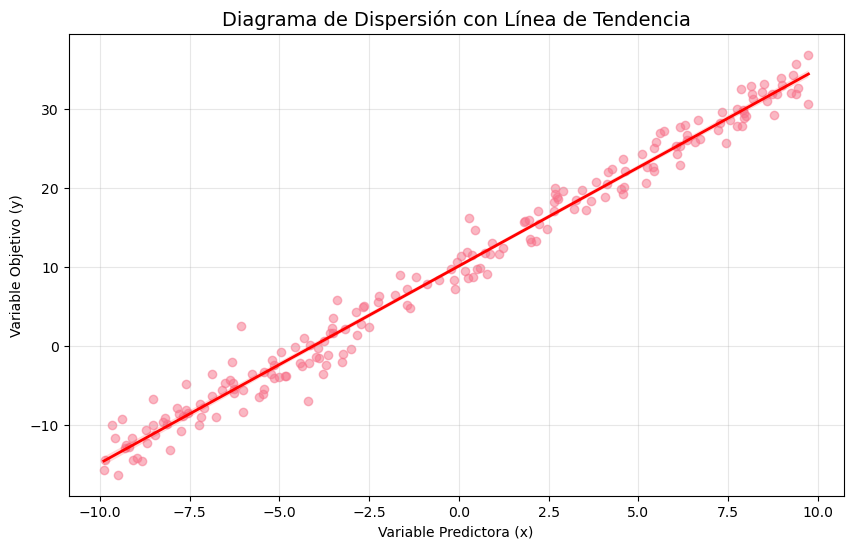

In [17]:
correlacion = datos.corr().iloc[0, 1]
print(f"Correlación entre x e y: {correlacion:.4f}")

# Interpretación de la correlación
if abs(correlacion) > 0.7:
    interpretacion = "Fuerte correlación lineal"
elif abs(correlacion) > 0.3:
    interpretacion = "Moderada correlación lineal"
else:
    interpretacion = "Débil correlación lineal"

print(f"Interpretación: {interpretacion}")
print(f"Dirección: {'Positiva' if correlacion > 0 else 'Negativa'}")

# Gráfico de correlación con línea de tendencia
plt.figure(figsize=(10, 6))
sns.regplot(x='x', y='y', data=datos, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red', 'linewidth': 2})
plt.title('Diagrama de Dispersión con Línea de Tendencia', fontsize=14)
plt.xlabel('Variable Predictora (x)')
plt.ylabel('Variable Objetivo (y)')
plt.grid(True, alpha=0.3)
plt.show()

 ## Preparación de Datos para el Modelo

In [19]:
# %% [python]
# Separar variables predictoras y objetivo
X = datos[['x']]  # Mantener como DataFrame para sklearn
y = datos['y']

print(f"Dimensiones: X {X.shape}, y {y.shape}")

# Dividir en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nTamaño conjunto de entrenamiento: {X_train.shape[0]} muestras")
print(f"Tamaño conjunto de prueba: {X_test.shape[0]} muestras")

# Estadísticas descriptivas por conjunto
print(f"\nEstadísticas de y_train: Media = {y_train.mean():.2f}, Desviación = {y_train.std():.2f}")
print(f"Estadísticas de y_test: Media = {y_test.mean():.2f}, Desviación = {y_test.std():.2f}")

Dimensiones: X (200, 1), y (200,)

Tamaño conjunto de entrenamiento: 160 muestras
Tamaño conjunto de prueba: 40 muestras

Estadísticas de y_train: Media = 9.22, Desviación = 14.93
Estadísticas de y_test: Media = 9.79, Desviación = 14.57



# Entrenamiento del Modelo de Regresión Lineal

In [22]:
# Crear y entrenar el modelo
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# Extraer parámetros del modelo
beta_0 = modelo_lineal.intercept_
beta_1 = modelo_lineal.coef_[0]

print("PARÁMETROS DEL MODELO:")
print("=" * 40)
print(f"Intercepto (β₀): {beta_0:.4f}")
print(f"Coeficiente (β₁): {beta_1:.4f}")
print(f"\nEcuación del modelo: y = {beta_1:.4f} * x + {beta_0:.4f}")
print(f"Ecuación real: y = 2.5000 * x + 10.0000")

# Calcular predicciones
y_pred_train = modelo_lineal.predict(X_train)
y_pred_test = modelo_lineal.predict(X_test)

PARÁMETROS DEL MODELO:
Intercepto (β₀): 10.1338
Coeficiente (β₁): 2.5105

Ecuación del modelo: y = 2.5105 * x + 10.1338
Ecuación real: y = 2.5000 * x + 10.0000



# Interpretación de los Coeficientes

## - **Intercepto (β₀)**: Valor esperado de y cuando x = 0
## - **Coeficiente (β₁)**: Cambio esperado en y por cada unidad de cambio en x

# Evaluación del Modelo

In [26]:
# Calcular métricas de evaluación
def calcular_metricas(y_real, y_pred, nombre_conjunto):
    """Calcula y muestra métricas de evaluación"""
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    
    print(f"\nMétricas - {nombre_conjunto}:")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"  Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  R² (Coeficiente de Determinación): {r2:.4f}")
    
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

# Evaluar en ambos conjuntos
metricas_train = calcular_metricas(y_train, y_pred_train, "Entrenamiento")
metricas_test = calcular_metricas(y_test, y_pred_test, "Prueba")


Métricas - Entrenamiento:
  Mean Squared Error (MSE): 3.5990
  Root Mean Squared Error (RMSE): 1.8971
  Mean Absolute Error (MAE): 1.5000
  R² (Coeficiente de Determinación): 0.9838

Métricas - Prueba:
  Mean Squared Error (MSE): 4.3385
  Root Mean Squared Error (RMSE): 2.0829
  Mean Absolute Error (MAE): 1.6775
  R² (Coeficiente de Determinación): 0.9791


#  Interpretación de R²
 
## El coeficiente de determinación R² indica la proporción de varianza en y que es explicada por el modelo:
## - R² = 1: Modelo perfecto
## - R² = 0: Modelo no explica nada
## - R² negativo: Modelo peor que la media simple

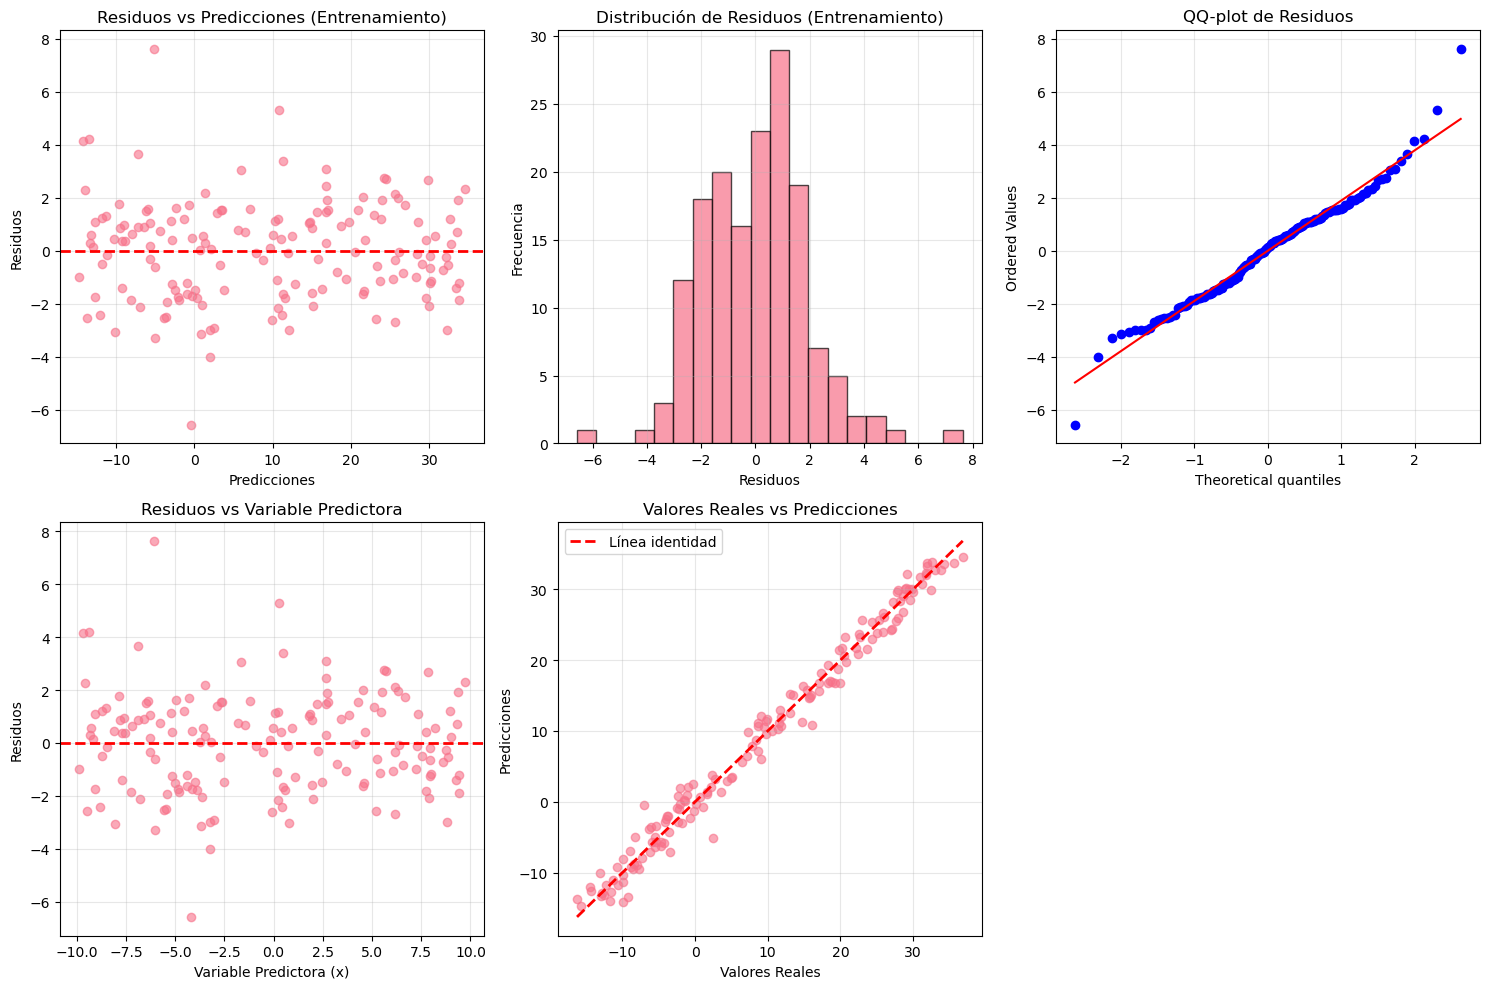

In [30]:

# Análisis de residuos
residuos_train = y_train - y_pred_train
residuos_test = y_test - y_pred_test

plt.figure(figsize=(15, 10))

# 1. Residuos vs Predicciones
plt.subplot(2, 3, 1)
plt.scatter(y_pred_train, residuos_train, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.title('Residuos vs Predicciones (Entrenamiento)')
plt.xlabel('Predicciones')
plt.ylabel('Residuos')
plt.grid(True, alpha=0.3)

# 2. Histograma de residuos
plt.subplot(2, 3, 2)
plt.hist(residuos_train, bins=20, alpha=0.7, edgecolor='black')
plt.title('Distribución de Residuos (Entrenamiento)')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)

# 3. QQ-plot para normalidad
plt.subplot(2, 3, 3)
stats.probplot(residuos_train, dist="norm", plot=plt)
plt.title('QQ-plot de Residuos')
plt.grid(True, alpha=0.3)

# 4. Residuos vs Variable Predictora
plt.subplot(2, 3, 4)
plt.scatter(X_train, residuos_train, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.title('Residuos vs Variable Predictora')
plt.xlabel('Variable Predictora (x)')
plt.ylabel('Residuos')
plt.grid(True, alpha=0.3)

# 5. Valores reales vs Predicciones
plt.subplot(2, 3, 5)
plt.scatter(y_train, y_pred_train, alpha=0.6)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 
         'r--', linewidth=2, label='Línea identidad')
plt.title('Valores Reales vs Predicciones')
plt.xlabel('Valores Reales')
plt.ylabel('Predicciones')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

VERIFICACIÓN DE SUPUESTOS DE LA REGRESIÓN LINEAL:
1. Linealidad: ✓ Verificada mediante gráfico de dispersión

2. Homocedasticidad (Prueba de Bartlett):
   Estadístico: 1.0290, p-valor: 0.3104
   ✓ Varianza constante

3. Normalidad (Prueba de Shapiro-Wilk):
   Estadístico: 0.9791, p-valor: 0.0157
   ✗ Residuos no normales

4. Independencia (Prueba Durbin-Watson):
   Estadístico: 1.9875
   ✓ No autocorrelación
ANÁLISIS ESTADÍSTICO DETALLADO (statsmodels):
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.984
Method:                 Least Squares   F-statistic:                     9568.
Date:                Thu, 05 Feb 2026   Prob (F-statistic):          2.84e-143
Time:                        17:24:21   Log-Likelihood:                -329.48
No. Observations:                 160   AIC:                        

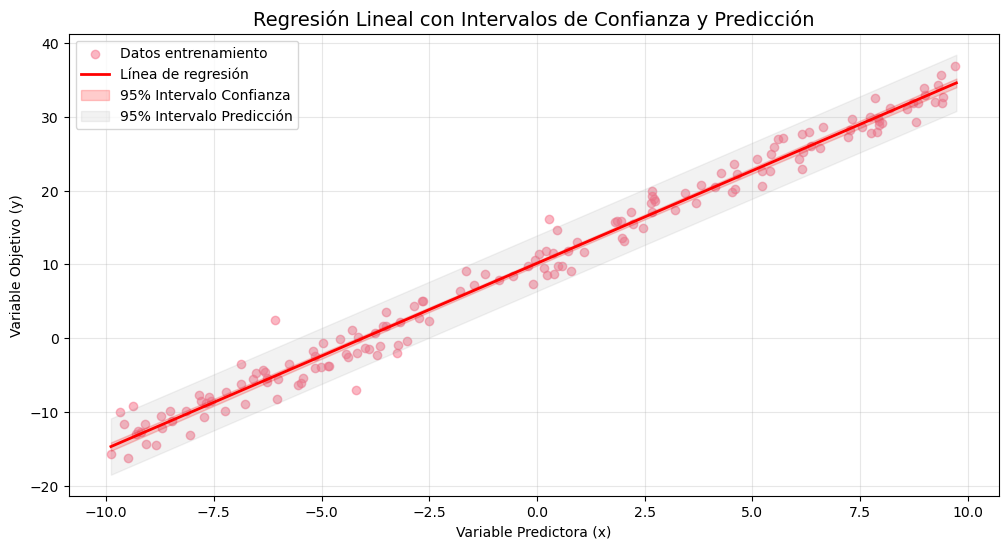

In [32]:
# ## Verificación de Supuestos del Modelo

# 
print("VERIFICACIÓN DE SUPUESTOS DE LA REGRESIÓN LINEAL:")
print("=" * 50)

# 1. Linealidad (ya verificada visualmente)
print("1. Linealidad: ✓ Verificada mediante gráfico de dispersión")

# 2. Homocedasticidad (varianza constante de residuos)
from scipy.stats import bartlett, levene

# Prueba de homocedasticidad
stat_bartlett, p_bartlett = bartlett(residuos_train[:len(residuos_train)//2], 
                                     residuos_train[len(residuos_train)//2:])
print(f"\n2. Homocedasticidad (Prueba de Bartlett):")
print(f"   Estadístico: {stat_bartlett:.4f}, p-valor: {p_bartlett:.4f}")
print(f"   {'✓ Varianza constante' if p_bartlett > 0.05 else '✗ Posible heterocedasticidad'}")

# 3. Normalidad de residuos
stat_norm, p_norm = stats.shapiro(residuos_train)
print(f"\n3. Normalidad (Prueba de Shapiro-Wilk):")
print(f"   Estadístico: {stat_norm:.4f}, p-valor: {p_norm:.4f}")
print(f"   {'✓ Residuos normales' if p_norm > 0.05 else '✗ Residuos no normales'}")

# 4. Independencia de residuos (no autocorrelación)
from statsmodels.stats.stattools import durbin_watson
dw_stat = durbin_watson(residuos_train)
print(f"\n4. Independencia (Prueba Durbin-Watson):")
print(f"   Estadístico: {dw_stat:.4f}")
print(f"   {'✓ No autocorrelación' if 1.5 < dw_stat < 2.5 else '✗ Posible autocorrelación'}")


# Análisis detallado con statsmodels
X_train_sm = sm.add_constant(X_train)  # Añadir constante para intercepto
modelo_sm = sm.OLS(y_train, X_train_sm).fit()

print("ANÁLISIS ESTADÍSTICO DETALLADO (statsmodels):")
print("=" * 50)
print(modelo_sm.summary())


# Interpretación de los resultados estadísticos
print("\nINTERPRETACIÓN DE RESULTADOS ESTADÍSTICOS:")
print("=" * 45)

# Coeficientes y significancia
for i, (coef, p_val) in enumerate(zip(modelo_sm.params, modelo_sm.pvalues)):
    variable = "Intercepto" if i == 0 else "x"
    print(f"{variable}: β = {coef:.4f}, p-valor = {p_val:.4f}", end="")
    if p_val < 0.05:
        print(" ✓ Significativo (p < 0.05)")
    else:
        print(" ✗ No significativo")

print(f"\nR² ajustado: {modelo_sm.rsquared_adj:.4f}")
print(f"Estadístico F: {modelo_sm.fvalue:.2f}, p-valor: {modelo_sm.f_pvalue:.4f}")


# ## Predicciones en Nuevos Datos


# Función para hacer predicciones con nuevos datos
def hacer_prediccion(modelo, nuevos_valores_x):
    """
    Realiza predicciones con nuevos valores de x
    
    Parameters:
    modelo: Modelo de regresión lineal entrenado
    nuevos_valores_x: Array, lista o valor individual de x
    
    Returns:
    predicciones: Array con las predicciones
    """
    if isinstance(nuevos_valores_x, (int, float)):
        nuevos_valores_x = [[nuevos_valores_x]]
    elif isinstance(nuevos_valores_x, (list, np.ndarray)):
        if len(np.array(nuevos_valores_x).shape) == 1:
            nuevos_valores_x = np.array(nuevos_valores_x).reshape(-1, 1)
    
    predicciones = modelo.predict(nuevos_valores_x)
    return predicciones

# Ejemplos de predicción
print("EJEMPLOS DE PREDICCIÓN:")
print("=" * 40)

valores_ejemplo = [-8, -4, 0, 4, 8]
for x_val in valores_ejemplo:
    prediccion = hacer_prediccion(modelo_lineal, x_val)[0]
    valor_real = 2.5 * x_val + 10  # Relación real
    error = abs(prediccion - valor_real)
    
    print(f"x = {x_val:5.1f}:")
    print(f"  Predicción: ŷ = {prediccion:6.2f}")
    print(f"  Valor real: y = {valor_real:6.2f}")
    print(f"  Error: {error:6.2f}")
    print("-" * 30)


# ## Intervalos de Confianza y Predicción


# Calcular intervalos de confianza para las predicciones
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_pred_range = modelo_lineal.predict(X_range)

# Usar statsmodels para intervalos de confianza
X_range_sm = sm.add_constant(X_range)
predictions = modelo_sm.get_prediction(X_range_sm)
pred_frame = predictions.summary_frame(alpha=0.05)  # 95% de confianza

plt.figure(figsize=(12, 6))

# Gráfico con intervalos de confianza
plt.scatter(X_train, y_train, alpha=0.5, label='Datos entrenamiento')
plt.plot(X_range, y_pred_range, 'r-', label='Línea de regresión', linewidth=2)

# Intervalo de confianza
plt.fill_between(X_range.flatten(), 
                 pred_frame['mean_ci_lower'], 
                 pred_frame['mean_ci_upper'], 
                 color='red', alpha=0.2, label='95% Intervalo Confianza')

# Intervalo de predicción
plt.fill_between(X_range.flatten(), 
                 pred_frame['obs_ci_lower'], 
                 pred_frame['obs_ci_upper'], 
                 color='gray', alpha=0.1, label='95% Intervalo Predicción')

plt.title('Regresión Lineal con Intervalos de Confianza y Predicción', fontsize=14)
plt.xlabel('Variable Predictora (x)')
plt.ylabel('Variable Objetivo (y)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

